# Task 1: Ensemble Learning on HW4 Data
**Approach:** 
1. Check the class balance and preprocess the data (one-hot encode categorical data, scale numerical data for the linear model)
2. Tune four different base models (random forest, extra trees, gradient boosting, and logistic regression) with randomized search and 5-fold CV on a split of the training data.
3. Combine the models into ensembles (soft voting, stacking) and then compare against the single models using CV AUC.
4. Check the winner on a held-out validation split, then refit on all labeled data and write the predictions to `test_result_HW6Ensemble.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier, StackingClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 72

### Load the data and inspect class balance

In [2]:
# Read and save the data sets from HW4
train = pd.read_csv("train_dataHW4.csv")
test = pd.read_csv("test_dataHW4.csv")

X = train.drop(columns="Class") # Features
y = train["Class"] # Labels (predicting the probability of class 2)

print("Train shape:", X.shape, "| Test shape:", test.shape)
print("Class balance:\n", y.value_counts(normalize=True).round(4))
print("Missing values in train", int(train.isna().sum().sum()))

Train shape: (7595, 24) | Test shape: (2532, 24)
Class balance:
 Class
1    0.8394
2    0.1606
Name: proportion, dtype: float64
Missing values in train 0


### Preprocessing
Categorical columns are one-hot encoded. Tree models do not need scaling, but logistic regression does so there are two preprocessors.

In [3]:
# Save categorical columns and numerical columns for different preprocessing
cat_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numeric_cols = X.columns.difference(cat_cols).tolist()

def make_preprocess(scale_numeric):
    num = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", num, numeric_cols)
    ])

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

### Tune base models
Each model gets its own randomized search (AUC, 5-fold CV, training split only).

In [4]:
def tune(name, estimator, space, scale, n_iter):
    # Pipeline does preprocessing and tunes model so encoding is re-fit in each CV fold
    pipe = Pipeline([("prep", make_preprocess(scale)), ("model", estimator)])
    n_iter = min(n_iter, len(ParameterGrid(space)))
    search = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1, return_train_score=True)
    search.fit(X_train, y_train)
    print(f"{name:<8}: best CV AUC = {search.best_score_:.4f}  {search.best_params_}")
    return search

spaces = {
    "Random forest": (RandomForestClassifier(n_estimators=300, random_state=SEED), False, 20, {
        "model__max_depth": [None, 6, 14, 20, 25], "model__min_samples_leaf": [1, 2, 4, 8], 
        "model__max_features": ["sqrt", "log2", 0.3]}),
    "Extra trees": (ExtraTreesClassifier(n_estimators=300, random_state=SEED), False, 20, {
        "model__max_depth": [None, 6, 14, 25, 40], "model__min_samples_leaf": [1, 2, 4, 8, 16],
        "model__max_features": ["sqrt", "log2", 0.3]}),
    "Gradient boosting": (HistGradientBoostingClassifier(random_state=SEED), False, 20, {
        "model__learning_rate": [0.03, 0.05, 0.1], "model__max_leaf_nodes": [5, 15, 31],
        "model__min_samples_leaf": [5, 10, 20, 50], "model__l2_regularization": [0, 0.1, 1],
        "model__max_iter": [200, 400]}),
    "Logistic regression": (LogisticRegression(max_iter=2000), True, 5, {
        "model__C": [0.01, 0.05, 0.1, 1, 10, 100]}),
}
searches = {n: tune(n, est, sp, scale, it) for n, (est, scale, it, sp) in spaces.items()}
tuned = {n: s.best_estimator_ for n, s in searches.items()}

Random forest: best CV AUC = 0.9313  {'model__min_samples_leaf': 2, 'model__max_features': 0.3, 'model__max_depth': None}
Extra trees: best CV AUC = 0.9271  {'model__min_samples_leaf': 2, 'model__max_features': 0.3, 'model__max_depth': 25}
Gradient boosting: best CV AUC = 0.9503  {'model__min_samples_leaf': 5, 'model__max_leaf_nodes': 15, 'model__max_iter': 400, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.1}
Logistic regression: best CV AUC = 0.8863  {'model__C': 0.05}


### Build the ensembles and compare


In [ ]:
def fresh(name): # Return an unfit copy of the `name` tuned pipeline
    return clone(tuned[name])

base_models = list(tuned)
models = {n: fresh(n) for n in base_models}
models["Soft vote (RF+ET)"] = VotingClassifier([
    ("rf", fresh("Random forest")), ("et", fresh("Extra trees"))], voting="soft")
models["Soft vote (all four)"] = VotingClassifier([(n[:3], fresh(n)) for n in base_models], voting="soft")
models["Stacking (all four)"] = StackingClassifier(
    [(n[:3], fresh(n)) for n in base_models], final_estimator=LogisticRegression(max_iter=2000), cv=cv, stack_method="predict_proba")
models["Soft vote (weighted)"] = VotingClassifier(
    [
        ("rf", fresh("Random forest")),
        # ("et", fresh("Extra trees")),
        ("gb", fresh("Gradient boosting")),
        # ("lr", fresh("Logistic regression")),
    ],
    voting="soft",
    weights=[1, 10], # best so far [1, 10] mean auc=0.9502 std=0.0091
)
cv_scores = {n: cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1) for n, m in models.items()}
comparison = (pd.DataFrame({"mean_cv_auc": {n: s.mean() for n, s in cv_scores.items()},
                            "std": {n: s.std() for n, s in cv_scores.items()}}).sort_values("mean_cv_auc"))
display(comparison.round(4))

,mean_cv_auc,std
Logistic regression,0.8863,0.0122
Extra trees,0.9271,0.0130
Random forest,0.9313,0.0068
Soft vote (RF+ET),0.9336,0.0096
Soft vote (all four),0.9373,0.0105
Stacking (all four),0.9432,0.0106
Soft vote (weighted),0.9502,0.0091
Gradient boosting,0.9503,0.0099


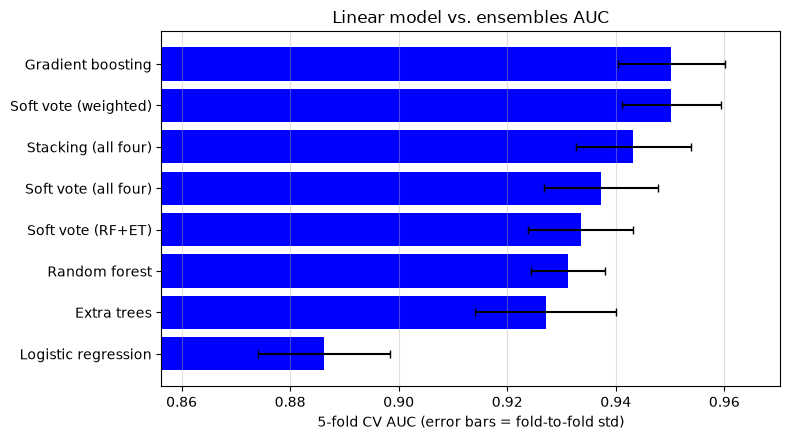

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(comparison.index, comparison["mean_cv_auc"], xerr=comparison["std"], capsize=3, color="blue")
ax.set_xlim(comparison["mean_cv_auc"].min() - 0.03, min(1, comparison["mean_cv_auc"].max() + 0.02))
ax.set_xlabel("5-fold CV AUC (error bars = fold-to-fold std)")
ax.set_title("Linear model vs. ensembles AUC")
ax.grid(axis="x", alpha=0.4)
plt.tight_layout(); plt.show()

In [21]:
best_name = "Soft vote (weighted)" # comparison["mean_cv_auc"].idxmax()
print("Selected ensemble:", best_name)


Selected ensemble: Soft vote (weighted)


### Check on held-out validation split

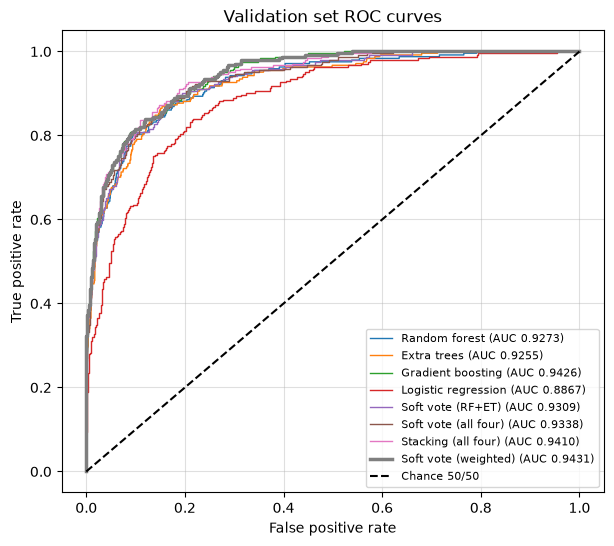

               model  validation_auc
 Logistic regression        0.886686
         Extra trees        0.925521
       Random forest        0.927305
   Soft vote (RF+ET)        0.930894
Soft vote (all four)        0.933767
 Stacking (all four)        0.941038
   Gradient boosting        0.942597
Soft vote (weighted)        0.943079


In [22]:
y_val_bin = (y_val == 2).astype(int)
fitted, rows = {}, []
plt.figure(figsize=(7, 6))
for n, m in models.items():
    m = clone(m).fit(X_train, y_train)
    fitted[n] = m
    p = m.predict_proba(X_val)[:, list(m.classes_).index(2)]
    auc = roc_auc_score(y_val_bin, p)
    rows.append((n, auc))
    fpr, tpr, _ = roc_curve(y_val_bin, p)
    plt.plot(fpr, tpr, lw=2.5 if n == best_name else 1, label=f"{n} (AUC {auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance 50/50")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Validation set ROC curves"); plt.legend(fontsize=8, loc="lower right")
plt.grid(alpha=0.4); plt.show()
print(pd.DataFrame(rows, columns=["model", "validation_auc"]).sort_values("validation_auc").to_string(index=False))

### Which features matter the most? (permutation importance of selected model)

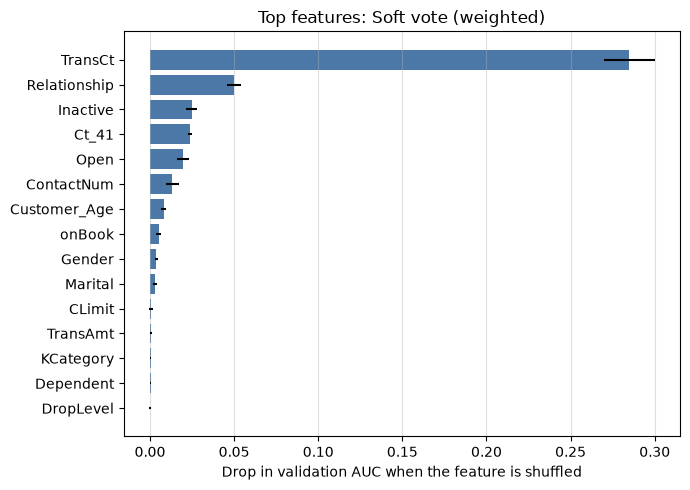

In [24]:
imp = permutation_importance(fitted[best_name], X_val, y_val, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
order = np.argsort(imp.importances_mean)[-15:]
plt.figure(figsize=(7, 5))
plt.barh(X.columns[order], imp.importances_mean[order], xerr=imp.importances_std[order], color="#4C78A8")
plt.xlabel("Drop in validation AUC when the feature is shuffled")
plt.title(f"Top features: {best_name}")
plt.grid(axis="x", alpha=0.4)
plt.tight_layout(); plt.show()

In [25]:
final_model = clone(models[best_name]).fit(X, y)

class2_index = list(final_model.classes_).index(2)
test_class2_prob = final_model.predict_proba(test)[:, class2_index]

assert len(test_class2_prob) == len(test), "row count mismatch"
print(f"Predictions: {len(test_class2_prob)} | min {test_class2_prob.min():.5f} | max {test_class2_prob.max():.5f}")

pd.DataFrame({"Class2_probability": test_class2_prob}).to_csv("test_result_HW6Ensemble.csv", index=False, header=False)

Predictions: 2532 | min 0.00007 | max 0.99602
